<a href="https://colab.research.google.com/github/DylanWeidner/Housing_Prices_King_County/blob/main/Housing_Prices_King_County.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Project Requirements

## Project: Predicting Housing Prices in King County

## Work on for 2 weeks

## Dataset
We will use the **King County House Sales dataset**:  
[House Sales Prediction (Kaggle)](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction)

- Contains information on **21,613 house sales** in King County, Washington (includes Seattle).
- Features include:
  - Square footage of living space and lot
  - Number of bedrooms and bathrooms
  - Floors, waterfront view, condition, grade
  - Year built and year renovated
  - Geographic location (latitude, longitude, zip code)
- Target variable: **Sale Price**

---

## Project Goal
- Build regression models to **predict housing prices** based on property features.
- Compare **Linear Regression, Ridge Regression, and Lasso Regression**.
- Evaluate models using metrics:
  - **R²** (variance explained)
  - **MAE** (mean absolute error)
  - **RMSE** (root mean squared error)

---

## Why This Matters
- Housing prices are influenced by many factors: size, location, condition, and more.
- Regression helps us **quantify relationships** and make predictions.
- This project connects data science techniques to a **real-world problem** in economics and urban planning.

---

## Deliverables
1. **Data Exploration**  
   - Summary statistics, distributions, correlations.
2. **Model Building**  
   - Fit Linear, Ridge, and Lasso regression models.
3. **Model Evaluation**  
   - Report R², MAE, RMSE for each model.
   - Interpret coefficients (which features matter most).
4. **Reflection**  
   - Discuss overfitting, regularization, and practical insights.

---

## Key Takeaway
By the end of this project, you will:
- Understand how regression applies to real-world housing data.
- Gain hands-on experience with **model building and evaluation**.
- Be able to explain trade-offs between different regression approaches.


#Imports for Project


In [238]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from google.colab import drive


#Import the dataset, and explore the data

CSV import, and looking at the first five rows of the dataset.

In [239]:
#Import dataset from my google drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/_Intro to data science/Project1/kc_house_data.csv'
df = pd.read_csv(file_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [240]:
pd.set_option('display.max_columns', None)

In [241]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


Look at some statistics about the data.

In [242]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


We have 21613 Records with 21 features in our dataset.

In [243]:
df.shape

(21613, 21)

Looking at the datatypes of our data.
The date field is not a datetime datatype. We will want to address that.


In [244]:
df.dtypes

,0
id,int64
date,object
price,float64
bedrooms,int64
bathrooms,float64
sqft_living,int64
sqft_lot,int64
floors,float64
waterfront,int64
view,int64


Look at how many unique values are in each column

In [245]:
df.nunique(dropna=False)

,0
id,21436
date,372
price,4028
bedrooms,13
bathrooms,30
sqft_living,1038
sqft_lot,9782
floors,6
waterfront,2
view,5


We have no Null values per the code below

In [246]:
df.isnull().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


In [247]:
df.isna().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


#Data Wrangling


---

We will try to clean bad data and fix any issues with the dataset

We had a record with 33 bedrooms. Let's look at it and address it

In [248]:
df[df['bedrooms'] == 33]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
15870,2402100895,20140625T000000,640000.0,33,1.75,1620,6000,1.0,0,0,5,7,1040,580,1947,0,98103,47.6878,-122.331,1330,4700


In [249]:
# this record seems to make no sense with the sqft and bedrooms. We will drop it.
df.iloc[15870]

,15870
id,2402100895
date,20140625T000000
price,640000.0
bedrooms,33
bathrooms,1.75
sqft_living,1620
sqft_lot,6000
floors,1.0
waterfront,0
view,0


In [250]:
#drop record
df = df.drop(index=15870)

In [251]:
# confirm record is gone
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161200e+04,2.161200e+04,21612.000000,21612.000000,21612.000000,2.161200e+04,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000
mean,4.580402e+09,5.400835e+05,3.369471,2.114774,2079.921016,1.510739e+04,1.494332,0.007542,0.234314,3.409356,7.656904,1788.425319,291.495697,1971.006247,84.406163,98077.938645,47.560047,-122.213891,1986.582871,12768.828984
std,2.876594e+09,3.671351e+05,0.907982,0.770177,918.456818,4.142142e+04,0.539991,0.086519,0.766334,0.650668,1.175477,828.094487,442.580931,29.373636,401.688123,53.505993,0.138564,0.140829,685.392610,27304.756179
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.218375e+05,3.000000,1.750000,1426.500000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.470975,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.619000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068825e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.250000
max,9.900000e+09,7.700000e+06,11.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [252]:
#look at 11 bedrooms record
df[df['bedrooms'] == 11]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
8757,1773100755,20140821T000000,520000.0,11,3.0,3000,4960,2.0,0,0,3,7,2400,600,1918,1999,98106,47.556,-122.363,1420,4960


In [253]:
#remove this record as well, as house size and price don't correlate with 11 bedrooms
df = df.drop(index=8757)

In [254]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161100e+04,2.161100e+04,21611.000000,21611.000000,21611.000000,2.161100e+04,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000
mean,4.580532e+09,5.400844e+05,3.369118,2.114733,2079.878442,1.510786e+04,1.494308,0.007542,0.234325,3.409375,7.656934,1788.397020,291.481421,1971.008699,84.317570,98077.937347,47.560047,-122.213884,1986.609088,12769.190320
std,2.876597e+09,3.671435e+05,0.906518,0.770171,918.456742,4.142232e+04,0.539992,0.086521,0.766350,0.650677,1.175496,828.103196,442.586196,29.372103,401.486212,53.506890,0.138567,0.140829,685.397631,27305.336262
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.217250e+05,3.000000,1.750000,1426.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.470950,-122.328000,1490.000000,5100.000000
50%,3.904931e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.620000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068850e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.500000
max,9.900000e+09,7.700000e+06,10.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [255]:
# We have 13 records with 0 bedrooms
df[df['bedrooms'] == 0]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
875,6306400140,20140612T000000,1095000.0,0,0.00,3064,4764,3.5,0,2,3,7,3064,0,1990,0,98102,47.6362,-122.322,2360,4000
3119,3918400017,20150205T000000,380000.0,0,0.00,1470,979,3.0,0,2,3,8,1470,0,2006,0,98133,47.7145,-122.356,1470,1399
3467,1453602309,20140805T000000,288000.0,0,1.50,1430,1650,3.0,0,0,3,7,1430,0,1999,0,98125,47.7222,-122.290,1430,1650
4868,6896300380,20141002T000000,228000.0,0,1.00,390,5900,1.0,0,0,2,4,390,0,1953,0,98118,47.5260,-122.261,2170,6000
6994,2954400190,20140624T000000,1295650.0,0,0.00,4810,28008,2.0,0,0,3,12,4810,0,1990,0,98053,47.6642,-122.069,4740,35061
8477,2569500210,20141117T000000,339950.0,0,2.50,2290,8319,2.0,0,0,3,8,2290,0,1985,0,98042,47.3473,-122.151,2500,8751
8484,2310060040,20140925T000000,240000.0,0,2.50,1810,5669,2.0,0,0,3,7,1810,0,2003,0,98038,47.3493,-122.053,1810,5685
9773,3374500520,20150429T000000,355000.0,0,0.00,2460,8049,2.0,0,0,3,8,2460,0,1990,0,98031,47.4095,-122.168,2520,8050
9854,7849202190,20141223T000000,235000.0,0,0.00,1470,4800,2.0,0,0,3,7,1470,0,1996,0,98065,47.5265,-121.828,1060,7200
12653,7849202299,20150218T000000,320000.0,0,2.50,1490,7111,2.0,0,0,3,7,1490,0,1999,0,98065,47.5261,-121.826,1500,4675


In [256]:
# drop 0 bedroom records
df = df[df['bedrooms'] != 0]

In [257]:
# Check they are gone
df[df['bedrooms'] == 0]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15


In [258]:
# check on 0 bathroom records
df[df['bathrooms'] == 0]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
1149,3421079032,20150217T000000,75000.0,1,0.0,670,43377,1.0,0,0,3,3,670,0,1966,0,98022,47.2638,-121.906,1160,42882
5832,5702500050,20141104T000000,280000.0,1,0.0,600,24501,1.0,0,0,2,3,600,0,1950,0,98045,47.5316,-121.749,990,22549
10481,203100435,20140918T000000,484000.0,1,0.0,690,23244,1.0,0,0,4,7,690,0,1948,0,98053,47.6429,-121.955,1690,19290


In [259]:
# we will remove these 0 bathroom records as I assume this is incorrect
df = df[df['bathrooms'] != 0]

In [260]:
# Look at records with more than 3 bathrooms
df[df['bathrooms'] > 3].groupby('bathrooms')['bathrooms'].value_counts()

,count
bathrooms,
3.25,589
3.50,731
3.75,155
4.00,136
4.25,79
4.50,100
4.75,23
5.00,21
5.25,13


In [261]:
df[df['bathrooms'] > 7]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
7252,6762700020,20141013T000000,7700000.0,6,8.00,12050,27600,2.5,0,3,4,13,8570,3480,1910,1987,98102,47.6298,-122.323,3940,8800
8546,424049043,20140811T000000,450000.0,9,7.50,4050,6504,2.0,0,0,3,7,4050,0,1996,0,98144,47.5923,-122.301,1448,3866
9254,9208900037,20140919T000000,6885000.0,6,7.75,9890,31374,2.0,0,4,3,13,8860,1030,2001,0,98039,47.6305,-122.240,4540,42730
12777,1225069038,20140505T000000,2280000.0,7,8.00,13540,307752,3.0,0,4,3,12,9410,4130,1999,0,98053,47.6675,-121.986,4850,217800


In [262]:
df[(df['bathrooms'] < 7) & (df['bathrooms'] > 5)]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
1164,1247600105,20141020T000000,5110800.0,5,5.25,8010,45517,2.0,1,4,3,12,5990,2020,1999,0,98033,47.6767,-122.211,3430,26788
1315,7558700030,20150413T000000,5300000.0,6,6.00,7390,24829,2.0,1,4,4,12,5000,2390,1991,0,98040,47.5631,-122.210,4320,24619
2626,7738500731,20140815T000000,4500000.0,5,5.50,6640,40014,2.0,1,4,3,12,6350,290,2004,0,98155,47.7493,-122.280,3030,23408
3020,3377900195,20140929T000000,2525000.0,4,5.50,6930,45100,1.0,0,0,4,11,4310,2620,1950,1991,98006,47.5547,-122.144,2560,37766
3100,622069006,20140820T000000,1500000.0,4,5.50,6550,217374,1.0,0,0,3,11,5400,1150,2006,0,98058,47.4302,-122.095,4110,50378
3121,7237500590,20141117T000000,1320000.0,4,5.25,6110,10369,2.0,0,0,3,11,6110,0,2005,0,98059,47.5285,-122.135,4190,10762
4024,9175600025,20141007T000000,800000.0,7,6.75,7480,41664,2.0,0,2,3,11,5080,2400,1953,0,98166,47.4643,-122.368,2810,33190
4035,685000115,20141007T000000,2150000.0,8,6.00,4340,9415,2.0,0,0,3,8,4340,0,1967,0,98004,47.6316,-122.202,2050,9100
4149,6447300265,20141014T000000,4000000.0,4,5.50,7080,16573,2.0,0,0,3,12,5760,1320,2008,0,98039,47.6151,-122.224,3140,15996
4411,2470100110,20140804T000000,5570000.0,5,5.75,9200,35069,2.0,0,0,3,13,6200,3000,2001,0,98039,47.6289,-122.233,3560,24345


In [263]:
# other bathrooms values look normal
# we will look at the sq foot lot column
df[df['sqft_lot'] == df['sqft_lot'].max()]
# value is normal as it is a farm

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
1719,1020069017,20150327T000000,700000.0,4,1.0,1300,1651359,1.0,0,3,4,6,1300,0,1920,0,98022,47.2313,-122.023,2560,425581


In [264]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.159500e+04,2.159500e+04,21595.000000,21595.000000,21595.000000,2.159500e+04,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000
mean,4.580705e+09,5.401992e+05,3.371475,2.115802,2080.300579,1.510030e+04,1.494096,0.007548,0.234313,3.409771,7.657976,1788.603195,291.697384,1971.003241,84.380042,98077.949386,47.560087,-122.213970,1986.676962,12759.017782
std,2.876767e+09,3.671501e+05,0.902643,0.768992,918.121966,4.141445e+04,0.539686,0.086553,0.766422,0.650480,1.173237,827.771962,442.678981,29.373926,401.628362,53.514939,0.138555,0.140724,685.236784,27275.598218
min,1.000102e+06,7.800000e+04,1.000000,0.500000,370.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,3.000000,370.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.220000e+05,3.000000,1.750000,1430.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471100,-122.328000,1490.000000,5100.000000
50%,3.904931e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.620000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.231000,1840.000000,7620.000000
75%,7.309000e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068600e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,10.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [265]:
# Value seems normal
df[df['sqft_living'] == df['sqft_living'].max()]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
12777,1225069038,20140505T000000,2280000.0,7,8.0,13540,307752,3.0,0,4,3,12,9410,4130,1999,0,98053,47.6675,-121.986,4850,217800


In [266]:
df['waterfront'].unique()

array([0, 1])

In [267]:
df['view'].unique()

array([0, 3, 4, 2, 1])

In [268]:
#most houses seem to get sold without being viewed
df['view'].value_counts()

,count
view,
0,19473
2,961
3,510
1,332
4,319


In [269]:
df['condition'].value_counts()

,count
condition,
3,14019
4,5677
5,1700
2,170
1,29


In [270]:
df['grade'].value_counts()

,count
grade,
7,8972
8,6065
9,2615
6,2038
10,1134
11,399
5,242
12,89
4,27


In [271]:
meanpricebyzip = round(df.groupby('zipcode')['price'].mean(), 2)
meanpricebyzip = meanpricebyzip.to_frame()

<Axes: xlabel='price', ylabel='zipcode'>

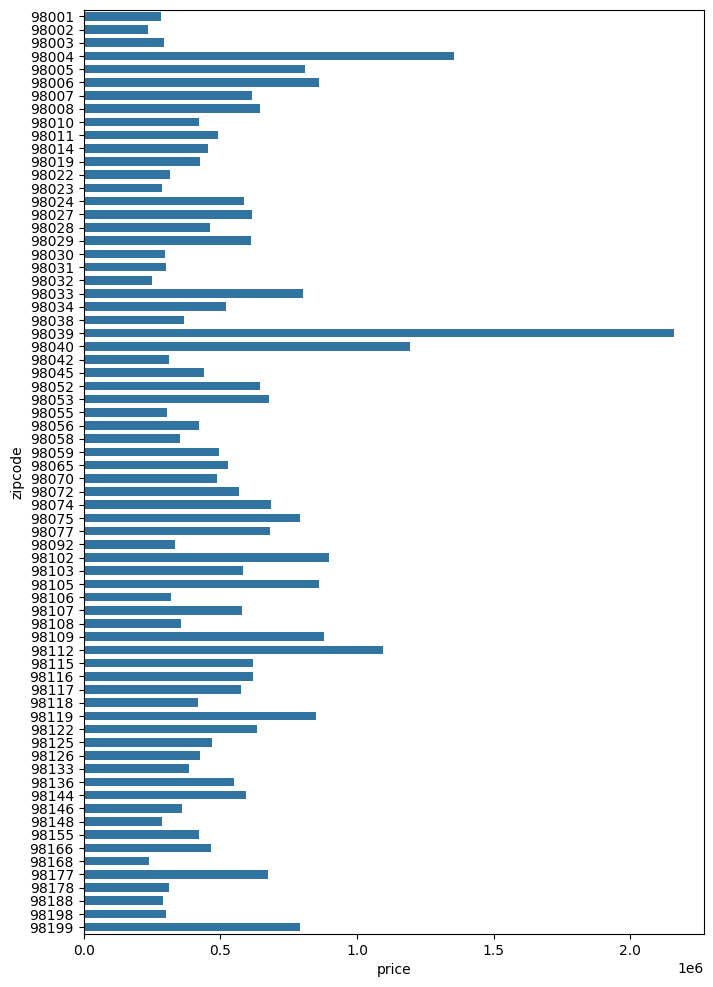

In [272]:
plt.figure(figsize=(8,12))
sns.barplot(data=meanpricebyzip, x='price', y='zipcode', gap=0.2, orient="h")

In [273]:
df[['price', 'zipcode']].corr()

,price,zipcode
price,1.000000,-0.053442
zipcode,-0.053442,1.000000


In [274]:
# there is a visual correlation between zipcode and house price.
# We will create dummy columns for model training

df_zips = df.copy()


In [275]:
df_zips = pd.get_dummies(df_zips, columns=['zipcode'], drop_first=True)

In [276]:
df_zips.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [277]:
df_zipswat = df_zips.copy()

In [278]:
df_zipswat = pd.get_dummies(df_zipswat, columns=['waterfront'], drop_first=True)

In [279]:
df_zipswat.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199,waterfront_1
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [280]:
df_zipswatview = df_zipswat.copy()

In [281]:
df_zipswatview = pd.get_dummies(df_zipswatview, columns=['view'], drop_first=True)

In [282]:
df_zipswatview.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199,waterfront_1,view_1,view_2,view_3,view_4
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [283]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [284]:
df_zipswatview_ren = df_zipswatview.copy()

In [285]:
df_zipswatview_ren['yr_renovated'].value_counts()

,count
yr_renovated,
0,20682
2014,91
2013,37
2003,36
2005,35
...,...
1948,1
1951,1
1959,1


In [286]:
was_renovated = []

for ren in df['yr_renovated']:
  if ren > 0:
    was_renovated.append(1)
  else:
    was_renovated.append(0)
was_renovated



[0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,


In [287]:
df_zipswatview_ren['renovated'] = was_renovated


In [288]:
df_zipswatview_ren = pd.get_dummies(df_zipswatview_ren, columns=['renovated'], drop_first=True)

In [289]:
df_zipswatview_ren.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199,waterfront_1,view_1,view_2,view_3,view_4,renovated_1
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


<Axes: xlabel='price', ylabel='waterfront'>

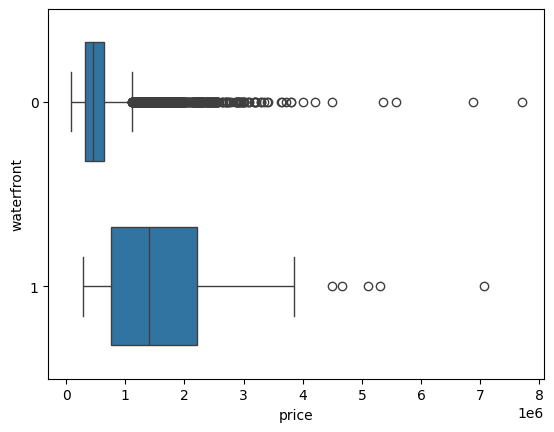

In [290]:
sns.boxplot(data=df, x='price', y='waterfront', gap=0.2, orient="h")

<Axes: xlabel='price', ylabel='yr_renovated'>

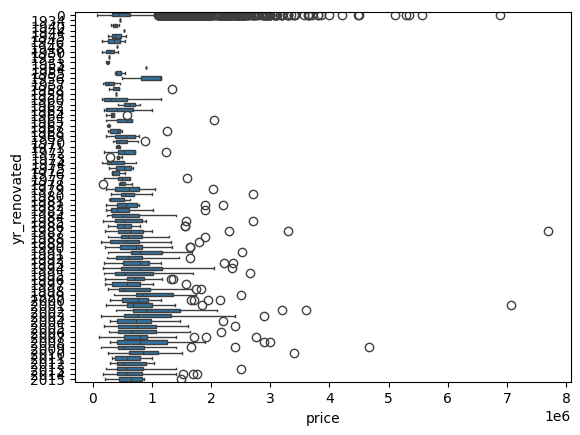

In [291]:
sns.boxplot(data=df, x='price', y='yr_renovated', gap=0.2, orient="h")

In [292]:
df[['price', 'waterfront']].corr()

,price,waterfront
price,1.000000,0.266438
waterfront,0.266438,1.000000


<Axes: xlabel='price', ylabel='view'>

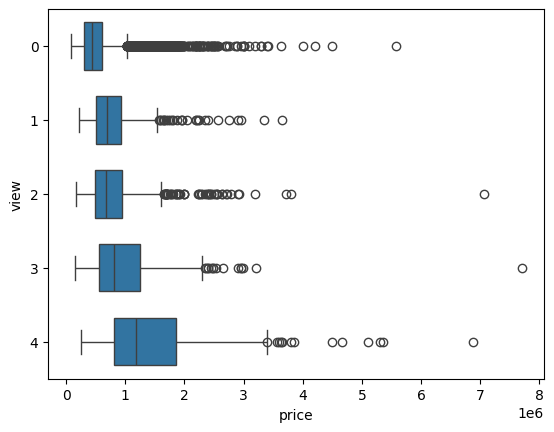

In [293]:
sns.boxplot(data=df, x='price', y='view', gap=0.2, orient="h")

In [294]:
# more times a house is viewed, the higher it sells for
df[['price', 'view']].corr()

,price,view
price,1.000000,0.397323
view,0.397323,1.000000


,price,sqft_living
price,1.00000,0.70194
sqft_living,0.70194,1.00000


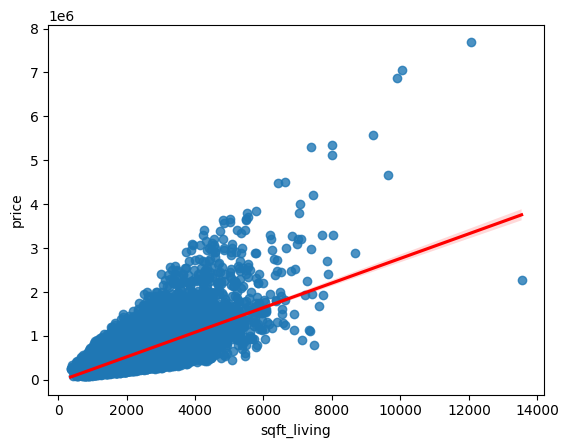

In [295]:
sns.regplot(data=df, x='sqft_living', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_living']].corr()

,price,sqft_above
price,1.000000,0.605405
sqft_above,0.605405,1.000000


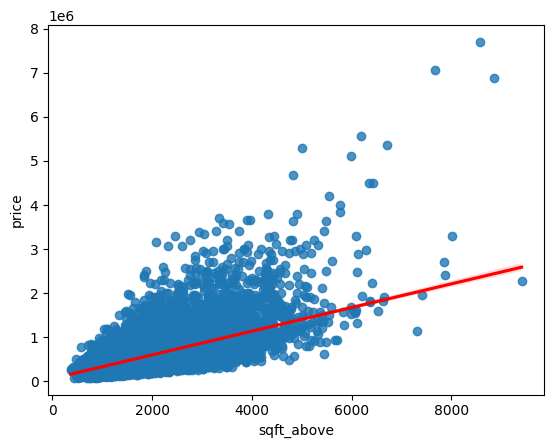

In [296]:
sns.regplot(data=df, x='sqft_above', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_above']].corr()

,price,sqft_basement
price,1.000000,0.323777
sqft_basement,0.323777,1.000000


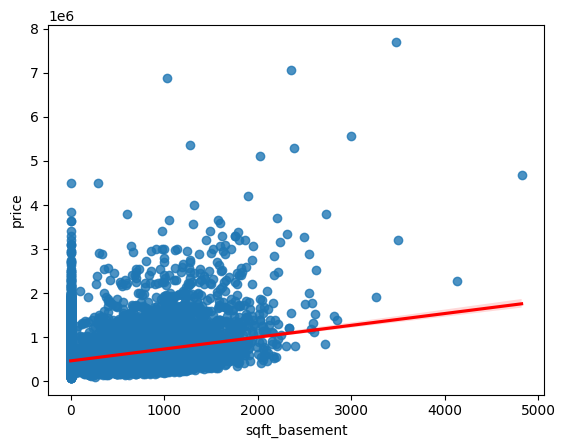

In [297]:
sns.regplot(data=df, x='sqft_basement', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_basement']].corr()

,price,yr_built
price,1.000000,0.053994
yr_built,0.053994,1.000000


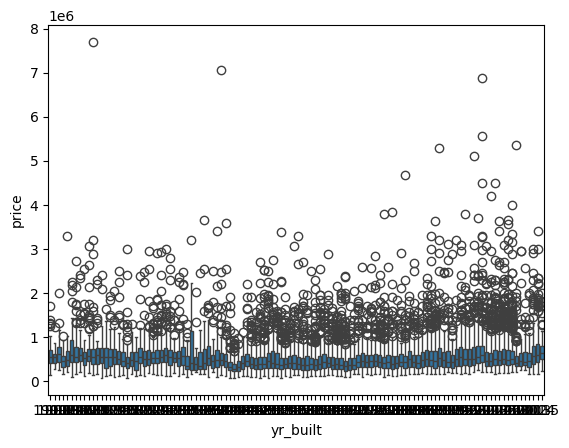

In [298]:
sns.boxplot(data=df, x='yr_built', y='price')
df[['price', 'yr_built']].corr()

In [299]:
# I will make new dataframe with yr built dummy columns to do testing
# yrbuilt does not seem to affect price as much
df_yrbuilt = df.copy()

In [300]:
df_yrbuilt = pd.get_dummies(df_yrbuilt, columns=['yr_built'], drop_first=True)

In [301]:
df_yrbuilt

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,yr_built_1901,yr_built_1902,yr_built_1903,yr_built_1904,yr_built_1905,yr_built_1906,yr_built_1907,yr_built_1908,yr_built_1909,yr_built_1910,yr_built_1911,yr_built_1912,yr_built_1913,yr_built_1914,yr_built_1915,yr_built_1916,yr_built_1917,yr_built_1918,yr_built_1919,yr_built_1920,yr_built_1921,yr_built_1922,yr_built_1923,yr_built_1924,yr_built_1925,yr_built_1926,yr_built_1927,yr_built_1928,yr_built_1929,yr_built_1930,yr_built_1931,yr_built_1932,yr_built_1933,yr_built_1934,yr_built_1935,yr_built_1936,yr_built_1937,yr_built_1938,yr_built_1939,yr_built_1940,yr_built_1941,yr_built_1942,yr_built_1943,yr_built_1944,yr_built_1945,yr_built_1946,yr_built_1947,yr_built_1948,yr_built_1949,yr_built_1950,yr_built_1951,yr_built_1952,yr_built_1953,yr_built_1954,yr_built_1955,yr_built_1956,yr_built_1957,yr_built_1958,yr_built_1959,yr_built_1960,yr_built_1961,yr_built_1962,yr_built_1963,yr_built_1964,yr_built_1965,yr_built_1966,yr_built_1967,yr_built_1968,yr_built_1969,yr_built_1970,yr_built_1971,yr_built_1972,yr_built_1973,yr_built_1974,yr_built_1975,yr_built_1976,yr_built_1977,yr_built_1978,yr_built_1979,yr_built_1980,yr_built_1981,yr_built_1982,yr_built_1983,yr_built_1984,yr_built_1985,yr_built_1986,yr_built_1987,yr_built_1988,yr_built_1989,yr_built_1990,yr_built_1991,yr_built_1992,yr_built_1993,yr_built_1994,yr_built_1995,yr_built_1996,yr_built_1997,yr_built_1998,yr_built_1999,yr_built_2000,yr_built_2001,yr_built_2002,yr_built_2003,yr_built_2004,yr_built_2005,yr_built_2006,yr_built_2007,yr_built_2008,yr_built_2009,yr_built_2010,yr_built_2011,yr_built_2012,yr_built_2013,yr_built_2014,yr_built_2015
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,0,98178,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1991,98125,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,0,98028,47.7379,-122.233,2720,8062,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Fals

,price,sqft_living15
price,1.00000,0.58528
sqft_living15,0.58528,1.00000


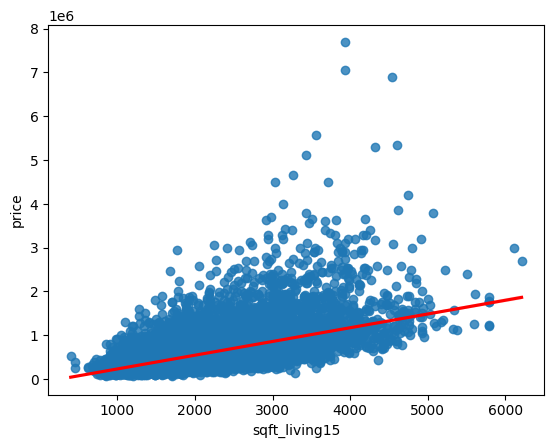

In [302]:
sns.regplot(data=df, x='sqft_living15', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_living15']].corr()

,price,sqft_lot15
price,1.00000,0.08284
sqft_lot15,0.08284,1.00000


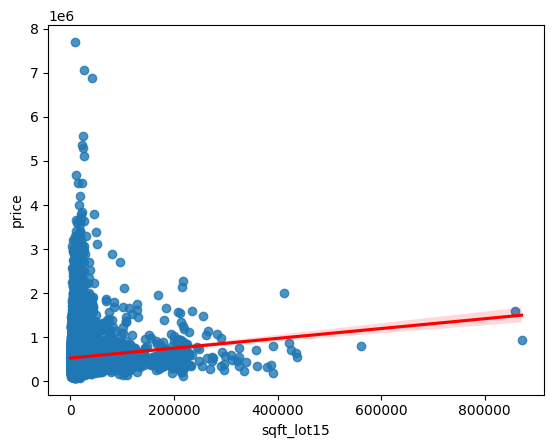

In [303]:
#this has almost no correlation
sns.regplot(data=df, x='sqft_lot15', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_lot15']].corr()

# Fit Linear Regression Models

In [304]:
# Method for evaluating models

def evaluate_models(model):

  model.fit(X_train, y_train)

  # train r2

  train_r2 = round(model.score(X_train, y_train), 2)



  # test r2

  test_r2 = round(model.score(X_test, y_test), 2)



  # train MAE

  train_mae = round(mean_absolute_error(y_train, model.predict(X_train)) ,2)



  # test mae

  test_mae = round(mean_absolute_error(y_test, model.predict(X_test)), 2)



  # train rmse

  train_rmse = round(root_mean_squared_error(y_train, model.predict(X_train)), 2)



  # test rmse

  test_rmse = round(root_mean_squared_error(y_test, model.predict(X_test)), 2)



  output_df = pd.DataFrame({

      'train': [train_r2, train_mae, train_rmse],

      'test': [test_r2, test_mae, test_rmse]},

                           index=['R2', 'MAE', 'RMSE'])

  display(output_df)

  print(f'\nNumber of non-zero coefficients: {np.sum(model.coef_ != 0)}\n')

  print(f'Coefficients: {model.coef_}')

###Linear Regression with normal dataframe

---



In [305]:
X = df[['sqft_living']]
y = df['price']

In [306]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [307]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

In [308]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in sqft_living, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.5
Test R2: 0.48
For every 1 increase in sqft_living, we would expect [282.99] increase in price


In [309]:
evaluate_models(lr)

,train,test
R2,0.50,0.48
MAE,174581.22,173263.50
RMSE,262762.30,257704.08



Number of non-zero coefficients: 1

Coefficients: [282.98868113]




---



In [310]:
X = df[['sqft_living', 'sqft_living15', 'sqft_basement', 'sqft_above']]
y = df['price']

In [311]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [312]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

In [313]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.51
Test R2: 0.49
For every 1 increase in Each Variable, we would expect [167.29  76.94 103.55  63.74] increase in price


In [314]:
evaluate_models(lr)

,train,test
R2,0.51,0.49
MAE,172895.06,171361.03
RMSE,260462.66,255867.33



Number of non-zero coefficients: 4

Coefficients: [167.29137313  76.9354498  103.55382197  63.73755117]




---



In [315]:
X = df[['sqft_living', 'sqft_living15', 'sqft_basement', 'sqft_above', 'view', 'waterfront']]
y = df['price']

In [316]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [317]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

In [318]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.56
Test R2: 0.54
For every 1 increase in Each Variable, we would expect [1.5243000e+02 5.6720000e+01 7.8900000e+01 7.3520000e+01 7.3565310e+04
 5.7560031e+05] increase in price


In [319]:
evaluate_models(lr)

,train,test
R2,0.56,0.54
MAE,165255.85,163966.52
RMSE,246118.99,241479.29



Number of non-zero coefficients: 6

Coefficients: [1.52426799e+02 5.67157450e+01 7.89028198e+01 7.35239787e+01
 7.35653107e+04 5.75600313e+05]




---



In [320]:
X = df.drop(columns=['price', 'date'])
y = df['price']

In [321]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [322]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

In [323]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.7
Test R2: 0.69
For every 1 increase in Each Variable, we would expect [-0.0000000e+00 -3.9017400e+04  4.2652050e+04  1.1135000e+02
  9.0000000e-02  5.9566000e+03  5.6607607e+05  5.4143530e+04
  2.8149420e+04  9.6578240e+04  7.1350000e+01  4.0000000e+01
 -2.6567300e+03  1.9610000e+01 -6.0412000e+02  5.9217686e+05
 -2.2240167e+05  2.4170000e+01 -3.8000000e-01] increase in price


In [324]:
evaluate_models(lr)

,train,test
R2,0.70,0.69
MAE,126763.12,125298.44
RMSE,202061.79,197284.68



Number of non-zero coefficients: 19

Coefficients: [-1.46709508e-06 -3.90173994e+04  4.26520517e+04  1.11346805e+02
  8.85202598e-02  5.95660337e+03  5.66076074e+05  5.41435299e+04
  2.81494236e+04  9.65782393e+04  7.13484357e+01  3.99983694e+01
 -2.65673330e+03  1.96140507e+01 -6.04117932e+02  5.92176861e+05
 -2.22401667e+05  2.41711287e+01 -3.76031662e-01]




---



###Linear Regression with normal dataframe, using zipcode dummy columns


In [325]:
X = df_zips.drop(columns=['price', 'date'])
y = df_zips['price']

In [326]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [327]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

In [328]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {list(lr.coef_.round(2))} increase in price')

Train R2: 0.81
Test R2: 0.8
For every 1 increase in Each Variable, we would expect [np.float64(-0.0), np.float64(-28530.6), np.float64(25053.94), np.float64(112.68), np.float64(0.2), np.float64(-45985.06), np.float64(635779.43), np.float64(58756.27), np.float64(25616.07), np.float64(56820.88), np.float64(95.63), np.float64(17.05), np.float64(-694.67), np.float64(17.82), np.float64(653078.98), np.float64(-73061.37), np.float64(12.02), np.float64(-0.1), np.float64(13329.26), np.float64(-38630.24), np.float64(522695.74), np.float64(87827.7), np.float64(94154.67), np.float64(38818.48), np.float64(46153.77), np.float64(47956.71), np.float64(-188392.55), np.float64(-131721.4), np.float64(-190665.15), np.float64(48328.19), np.float64(-53945.03), np.float64(5007.03), np.float64(24356.61), np.float64(-186972.04), np.float64(48157.17), np.float64(-43359.74), np.float64(-64675.02), np.float64(-55828.37), np.float64(112235.55), np.float64(-81383.71), np.float64(-10816.52), np.float64(1177847.6), n

In [329]:
evaluate_models(lr)

,train,test
R2,0.81,0.80
MAE,96905.62,95628.00
RMSE,161270.54,160149.25



Number of non-zero coefficients: 87

Coefficients: [-8.00407868e-07 -2.85306020e+04  2.50539410e+04  1.12678083e+02
  2.02355300e-01 -4.59850637e+04  6.35779435e+05  5.87562705e+04
  2.56160698e+04  5.68208787e+04  9.56289058e+01  1.70498642e+01
 -6.94674741e+02  1.78210008e+01  6.53078981e+05 -7.30613709e+04
  1.20190868e+01 -1.00768212e-01  1.33292643e+04 -3.86302380e+04
  5.22695737e+05  8.78276971e+04  9.41546739e+04  3.88184790e+04
  4.61537701e+04  4.79567130e+04 -1.88392552e+05 -1.31721396e+05
 -1.90665152e+05  4.83281858e+04 -5.39450292e+04  5.00702859e+03
  2.43566138e+04 -1.86972042e+05  4.81571749e+04 -4.33597373e+04
 -6.46750180e+04 -5.58283665e+04  1.12235550e+05 -8.13837051e+04
 -1.08165195e+04  1.17784760e+06  3.34722763e+05 -4.05931892e+04
 -2.63758345e+03 -2.34734526e+04 -5.27243306e+04 -6.46377961e+04
 -4.49192256e+04 -6.90307884e+04 -5.18390140e+04 -6.22371848e+04
 -9.86151527e+04 -1.49872769e+05 -3.75406092e+04 -2.53540247e+04
 -1.77410859e+05 -4.33010087e+04  2.81

###Linear Regression with normal dataframe, using zipcode, waterfront, view dummy columns


In [330]:
X = df_zipswatview.drop(columns=['price', 'date'])
y = df_zipswatview['price']

In [331]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [332]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

In [333]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {list(lr.coef_.round(2))} increase in price')

Train R2: 0.81
Test R2: 0.8
For every 1 increase in Each Variable, we would expect [np.float64(-0.0), np.float64(-28423.09), np.float64(25446.33), np.float64(112.19), np.float64(0.21), np.float64(-45778.22), np.float64(25082.67), np.float64(56946.67), np.float64(95.51), np.float64(16.67), np.float64(-721.01), np.float64(16.98), np.float64(652900.8), np.float64(-70719.31), np.float64(12.72), np.float64(-0.1), np.float64(13167.08), np.float64(-36295.28), np.float64(520349.98), np.float64(85531.62), np.float64(93439.21), np.float64(38271.15), np.float64(46213.48), np.float64(48269.38), np.float64(-188903.9), np.float64(-130480.22), np.float64(-191205.26), np.float64(52711.12), np.float64(-53524.75), np.float64(7353.08), np.float64(24631.17), np.float64(-188028.26), np.float64(47828.09), np.float64(-43386.11), np.float64(-65198.07), np.float64(-54764.95), np.float64(113338.44), np.float64(-81794.8), np.float64(-11825.12), np.float64(1175466.46), np.float64(336302.67), np.float64(-40733.8),

In [334]:
evaluate_models(lr)

,train,test
R2,0.81,0.80
MAE,96446.96,95286.33
RMSE,160555.08,159648.29



Number of non-zero coefficients: 90

Coefficients: [-8.18763483e-07 -2.84230903e+04  2.54463289e+04  1.12188926e+02
  2.05574594e-01 -4.57782243e+04  2.50826675e+04  5.69466745e+04
  9.55131550e+01  1.66689064e+01 -7.21006528e+02  1.69800359e+01
  6.52900799e+05 -7.07193127e+04  1.27179176e+01 -1.04934345e-01
  1.31670760e+04 -3.62952752e+04  5.20349979e+05  8.55316222e+04
  9.34392137e+04  3.82711472e+04  4.62134785e+04  4.82693843e+04
 -1.88903903e+05 -1.30480220e+05 -1.91205262e+05  5.27111218e+04
 -5.35247474e+04  7.35307956e+03  2.46311723e+04 -1.88028262e+05
  4.78280948e+04 -4.33861056e+04 -6.51980657e+04 -5.47649458e+04
  1.13338441e+05 -8.17948049e+04 -1.18251153e+04  1.17546646e+06
  3.36302669e+05 -4.07337973e+04 -1.74356470e+03 -2.37837766e+04
 -5.37160503e+04 -6.41762992e+04 -4.41021802e+04 -6.99131211e+04
 -5.20991827e+04 -6.08290124e+04 -9.01158990e+04 -1.50142699e+05
 -3.90948258e+04 -2.58562669e+04 -1.78462427e+05 -4.33968788e+04
  2.80324616e+05  7.98735763e+04  2.28

###Linear Regression with normal dataframe, yrbuilt dummy columns


In [335]:
X = df_yrbuilt.drop(columns=['price', 'date'])
y = df_yrbuilt['price']

In [336]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [337]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

In [338]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {list(lr.coef_.round(2))} increase in price')

Train R2: 0.71
Test R2: 0.7
For every 1 increase in Each Variable, we would expect [np.float64(-0.0), np.float64(-34293.43), np.float64(43204.93), np.float64(108.42), np.float64(0.09), np.float64(-13286.62), np.float64(573712.52), np.float64(54070.88), np.float64(30317.38), np.float64(100816.04), np.float64(68.09), np.float64(40.33), np.float64(17.12), np.float64(-750.92), np.float64(579146.47), np.float64(-203419.33), np.float64(26.22), np.float64(-0.28), np.float64(108664.55), np.float64(142386.6), np.float64(67068.19), np.float64(173656.75), np.float64(209121.48), np.float64(167079.52), np.float64(139231.12), np.float64(108578.65), np.float64(145343.55), np.float64(176407.19), np.float64(115850.26), np.float64(115046.52), np.float64(106464.79), np.float64(130904.63), np.float64(123576.22), np.float64(106503.56), np.float64(106251.07), np.float64(101862.1), np.float64(93134.24), np.float64(105968.01), np.float64(107900.89), np.float64(130067.68), np.float64(157445.25), np.float64(104

In [339]:
evaluate_models(lr)

,train,test
R2,0.71,0.70
MAE,125109.65,124284.73
RMSE,199062.98,194907.13



Number of non-zero coefficients: 133

Coefficients: [-1.59723789e-06 -3.42934329e+04  4.32049318e+04  1.08416055e+02
  9.38051657e-02 -1.32866170e+04  5.73712522e+05  5.40708822e+04
  3.03173777e+04  1.00816037e+05  6.80880958e+01  4.03279495e+01
  1.71172699e+01 -7.50920390e+02  5.79146474e+05 -2.03419330e+05
  2.62178803e+01 -2.81279904e-01  1.08664553e+05  1.42386599e+05
  6.70681904e+04  1.73656753e+05  2.09121483e+05  1.67079524e+05
  1.39231120e+05  1.08578649e+05  1.45343555e+05  1.76407193e+05
  1.15850260e+05  1.15046525e+05  1.06464792e+05  1.30904633e+05
  1.23576217e+05  1.06503558e+05  1.06251074e+05  1.01862101e+05
  9.31342383e+04  1.05968009e+05  1.07900893e+05  1.30067685e+05
  1.57445246e+05  1.04642506e+05  1.11273671e+05  1.17001183e+05
  1.18250094e+05  9.40106952e+04  5.88363770e+04  7.05128916e+04
  1.10060269e+05  8.09901681e+04  1.01403591e+05  6.03436024e+04
  1.26993368e+05  1.12655159e+05  9.29800256e+04  6.86902013e+04
  6.24286763e+04  6.88296252e+04  8.1

###Linear Regression with normal dataframe, using zipcode, waterfront, view dummy columns. And Renovated Column.

In [340]:
X = df_zipswatview_ren.drop(columns=['price', 'date', 'yr_renovated', 'id'])
y = df_zipswatview_ren['price']

In [341]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [342]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

In [343]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {list(lr.coef_.round(2))} increase in price')

Train R2: 0.81
Test R2: 0.8
For every 1 increase in Each Variable, we would expect [np.float64(-28512.72), np.float64(25135.94), np.float64(112.38), np.float64(0.21), np.float64(-46989.58), np.float64(24861.07), np.float64(56625.77), np.float64(95.94), np.float64(16.44), np.float64(-698.94), np.float64(192149.29), np.float64(-143491.13), np.float64(12.89), np.float64(-0.09), np.float64(40608.63), np.float64(-12733.45), np.float64(690271.73), np.float64(256679.95), np.float64(240763.29), np.float64(210805.71), np.float64(221338.11), np.float64(102044.87), np.float64(45700.74), np.float64(91287.21), np.float64(54162.95), np.float64(49713.33), np.float64(-38345.9), np.float64(173327.41), np.float64(161746.49), np.float64(43142.09), np.float64(206473.43), np.float64(13241.41), np.float64(7633.59), np.float64(-2082.16), np.float64(314940.99), np.float64(135785.74), np.float64(57174.66), np.float64(1350263.98), np.float64(479961.96), np.float64(19306.71), np.float64(133387.98), np.float64(18

In [344]:
evaluate_models(lr)

,train,test
R2,0.81,0.80
MAE,96060.66,95017.00
RMSE,160343.66,159564.23



Number of non-zero coefficients: 89

Coefficients: [-2.85127248e+04  2.51359435e+04  1.12379445e+02  2.05088605e-01
 -4.69895787e+04  2.48610745e+04  5.66257709e+04  9.59388999e+01
  1.64405415e+01 -6.98935935e+02  1.92149294e+05 -1.43491130e+05
  1.28926593e+01 -9.13960128e-02  4.06086309e+04 -1.27334509e+04
  6.90271727e+05  2.56679950e+05  2.40763286e+05  2.10805713e+05
  2.21338105e+05  1.02044874e+05  4.57007416e+04  9.12872055e+04
  5.41629480e+04  4.97133291e+04 -3.83458957e+04  1.73327414e+05
  1.61746491e+05  4.31420946e+04  2.06473430e+05  1.32414145e+04
  7.63359353e+03 -2.08216126e+03  3.14940992e+05  1.35785742e+05
  5.71746612e+04  1.35026398e+06  4.79961965e+05  1.93067082e+04
  1.33387976e+05  1.81273122e+05  1.57319894e+05  3.24440485e+04
  7.78665474e+04  2.57599300e+04  6.53988151e+04  9.25742537e+04
 -2.86279355e+04  8.74575510e+04  1.45518395e+05  1.43670286e+05
  6.24398352e+04 -1.64002068e+04  4.52656723e+05  2.67862372e+05
  4.15242455e+05  9.92383807e+04  2.76

# Fit Ridge Regression Model

---



In [345]:
ridge = Ridge()
evaluate_models(ridge)

,train,test
R2,0.81,0.80
MAE,96214.43,95097.01
RMSE,160441.87,159432.87



Number of non-zero coefficients: 89

Coefficients: [-2.86645211e+04  2.55734403e+04  1.12342482e+02  2.05960418e-01
 -4.57811928e+04  2.50161984e+04  5.72792354e+04  9.54602988e+01
  1.68830964e+01 -7.36638602e+02  4.55542664e+05 -1.09414604e+05
  1.29891009e+01 -9.72189754e-02  1.80431467e+04 -3.37011866e+04
  5.83149955e+05  1.50551454e+05  1.49051382e+05  1.04986580e+05
  1.14711562e+05  6.57318483e+04 -9.41410972e+04 -3.83933606e+04
 -8.90429722e+04  4.61488067e+04 -5.53448017e+04  7.39570446e+04
  7.68059579e+04 -9.54509515e+04  1.10012344e+05 -2.55156111e+04
 -4.03231410e+04 -3.90655218e+04  1.92693472e+05  4.73318526e+03
  1.25768479e+04  1.21346705e+06  3.88621967e+05 -2.10852223e+04
  5.23843151e+04  5.73517785e+04  3.05782077e+04 -2.97224173e+04
  1.61950782e+03 -3.48606911e+04 -8.01792708e+03 -4.63383549e+02
 -7.04369666e+04 -5.41569923e+04  3.36928760e+04  4.07874827e+04
 -8.00121447e+04 -3.79589415e+04  3.41578658e+05  1.51365633e+05
  2.98040755e+05  2.14447286e+04  1.62

# Fit Lasso Regression Models

---



In [346]:
lasso = Lasso(alpha=1)
evaluate_models(lasso)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.080e+14, tolerance: 2.222e+11
  model = cd_fast.enet_coordinate_descent(


,train,test
R2,0.81,0.80
MAE,96075.24,95021.50
RMSE,160347.02,159551.09



Number of non-zero coefficients: 89

Coefficients: [-2.85074424e+04  2.51763196e+04  2.35124134e+02  2.05542091e-01
 -4.68162376e+04  2.48820138e+04  5.66702370e+04 -2.68848935e+01
 -1.06280809e+02 -7.02537129e+02  2.45067980e+05 -1.30847540e+05
  1.28852053e+01 -9.23579451e-02  3.64686162e+04 -1.58044086e+04
  6.69828407e+05  2.35871558e+05  2.22652232e+05  1.89783850e+05
  1.99928805e+05  9.39789426e+04  1.78533153e+04  6.33611288e+04
  2.41204279e+04  4.81606056e+04 -4.03459002e+04  1.52094285e+05
  1.44282166e+05  1.58703007e+04  1.86495164e+05  5.70933461e+03
 -1.58598528e+03 -8.51131899e+03  2.90896543e+05  1.09920954e+05
  4.76167024e+04  1.32938161e+06  4.62643274e+05  1.10767095e+04
  1.14949329e+05  1.56407008e+05  1.31263669e+05  2.03227395e+04
  6.28394426e+04  1.36549830e+04  5.07018534e+04  7.23069924e+04
 -3.51877277e+04  5.89847178e+04  1.22651355e+05  1.22484466e+05
  3.33392452e+04 -2.04444042e+04  4.32398272e+05  2.45913649e+05
  3.93140338e+05  8.49261143e+04  2.55

# Conclusion

In this project, I built and evaluated several regression models to predict housing prices in King County.

Initial tests with linear regression gave me an r2 of about 0.5. Size is the strongest predictor, but only seems to explain about 50% of the variance.

After running linear regression  on all of the features, plus dummy coded zip codes we saw an increase in the r2 to about 0.81. This is due to the zip codes having been treated by the model as a numerical data type, when in fact they are categorical data types, and zip code dictates house price greatly.

I tried to use Lasso and Ridge regression, and didn’t see any improvement or loss in the r2 value. This seems to suggest that the relationship in the data is fairly linear, and does not require the use of Regularized models to explain the data.

Key Takeaways
* Importance choosing Features: Converting categorical fields like zipcode into dummy values, I saw a major increase in the r2 value.  I attempted this with waterfront, and view, but didn’t see such an increase in the r2.
* Regularization: I did not observe overfitting with basic Linear Regression. So regularizing with Ridge and Lasso did not seem to have a very large affect on the r2 value.
